# KMA/MSM – Přednáška 4: Vícerozměrná data

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází přednášku P04. Všechny výpočty jsou na datech Iris ($n=150$, $k=4$) nebo na simulovaných datech.

## Obsah

1. Datová matice
2. Standardizace, normalizace a vícerozměrná standardizace (whitening)
3. Výběrové statistiky – maticové vzorce, vychýlení $S_0$
4. Robustní a regularizované odhady (MCD, Ledoit–Wolf, James–Stein)
5. Centrální limitní věta ve více dimenzích
6. Wishartovo a Hotellingovo rozdělení – ověření simulací
7. Jednorozměrná vizualizace (histogram, KDE, violin, EDF, P-P a Q-Q graf)
8. Vícerozměrná vizualizace (elipsy, Q-Q graf Mahalanobisových vzdáleností, pairplot, 2D histogram a KDE)
9. Úlohy

**Značení:** $n$ počet pozorování, $k$ dimenze, $S$ korigovaná výběrová varianční matice (dělitel $n-1$), $S_0$ maximálně věrohodný odhad (dělitel $n$).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_iris

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
RNG = np.random.default_rng(2026)

# 1. Datová matice

Datová matice $\mathcal X$ je typu $n\times k$: řádky jsou pozorování (objekty), sloupce proměnné.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["druh"] = df["target"].map(dict(enumerate(iris.target_names)))
X = iris.data.to_numpy()
n, k = X.shape
print("n =", n, " k =", k)
df.head()

n = 150  k = 4


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,druh
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
df.groupby("druh")[iris.feature_names].mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
druh,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Průměry se mezi druhy výrazně liší hlavně u délky a šířky okvětního lístku (petal) – to uvidíme i na grafech.

# 2. Standardizace a normalizace

* **standardizace po sloupcích:** $z_{ij}=(x_{ij}-\bar x_j)/s_j$ – nulový průměr, jednotkový rozptyl, tvar rozdělení se nemění,
* **normalizace (min–max):** $x'_{ij}=(x_{ij}-\min_j)/(\max_j-\min_j)\in\langle0,1\rangle$ – citlivá na odlehlé hodnoty,
* **normalizace po řádcích:** $\boldsymbol x_i/\|\boldsymbol x_i\|$ – zachová jen směr vektoru.

Pozor: `StandardScaler` dělí směrodatnou odchylkou s dělitelem $n$ (`ddof=0`).

In [4]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, normalize

Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
Z2 = StandardScaler().fit_transform(X)
print("průměry Z:", Z.mean(axis=0).round(12))
print("sm. odch. Z (ddof=1):", Z.std(axis=0, ddof=1))
print("poměr Z2/Z =", (Z2 / Z)[0], " sqrt(n/(n-1)) =", np.sqrt(n / (n - 1)))

N = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
print("MinMaxScaler souhlasí:", np.allclose(N, MinMaxScaler().fit_transform(X)))
R = normalize(X, norm="l2")
print("délky řádků po normalizaci:", np.linalg.norm(R, axis=1)[:5])

průměry Z: [-0. -0. -0. -0.]
sm. odch. Z (ddof=1): [1. 1. 1. 1.]
poměr Z2/Z = [1.0034 1.0034 1.0034 1.0034]  sqrt(n/(n-1)) = 1.0033500931359767
MinMaxScaler souhlasí: True
délky řádků po normalizaci: [1. 1. 1. 1. 1.]


Standardizace po sloupcích **neodstraní korelace** – korelační matice standardizovaných dat je stejná jako u původních dat:

In [5]:
print(np.round(np.cov(Z, rowvar=False), 3))

[[ 1.    -0.118  0.872  0.818]
 [-0.118  1.    -0.428 -0.366]
 [ 0.872 -0.428  1.     0.963]
 [ 0.818 -0.366  0.963  1.   ]]


### Vícerozměrná standardizace (whitening)

$\boldsymbol z_i=S^{-1/2}(\boldsymbol x_i-\bar{\boldsymbol x})$, kde $S^{-1/2}$ je symetrická odmocnina z $S^{-1}$ (přes spektrální rozklad $S=V\Lambda V^T$, $S^{-1/2}=V\Lambda^{-1/2}V^T$). Transformovaná data mají výběrovou varianční matici $\boldsymbol I$.

In [6]:
S = np.cov(X, rowvar=False)
lam, V = np.linalg.eigh(S)
S_inv_half = V @ np.diag(lam ** -0.5) @ V.T
W = (X - X.mean(axis=0)) @ S_inv_half          # S^{-1/2} je symetrická
print(np.round(np.cov(W, rowvar=False), 10))

# Mahalanobisova vzdálenost = eukleidovská vzdálenost po whiteningu
d2_maha = np.einsum("ij,jk,ik->i", X - X.mean(0), np.linalg.inv(S), X - X.mean(0))
print("shoda d^2:", np.allclose(d2_maha, (W ** 2).sum(axis=1)))

[[ 1.  0.  0. -0.]
 [ 0.  1. -0.  0.]
 [ 0. -0.  1.  0.]
 [-0.  0.  0.  1.]]
shoda d^2: True


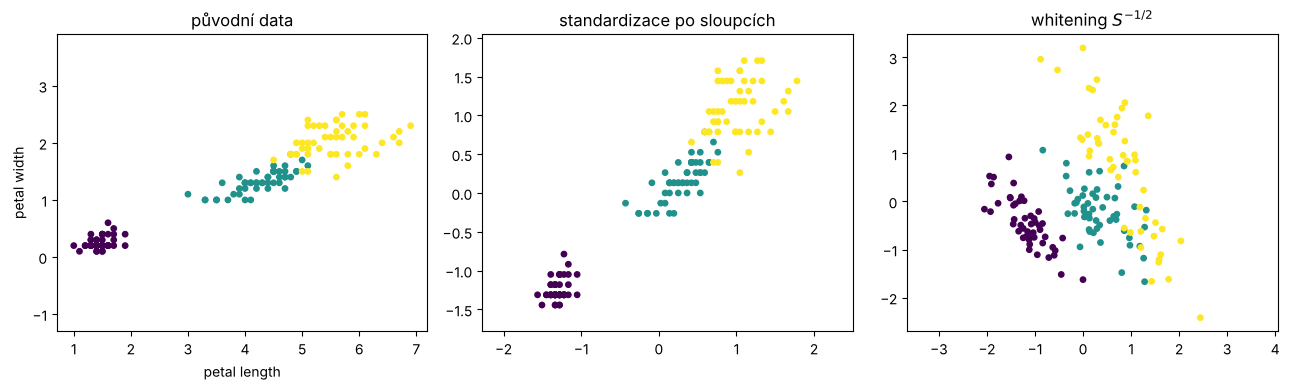

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
pairs = [(X[:, 2], X[:, 3], "původní data"), (Z[:, 2], Z[:, 3], "standardizace po sloupcích"),
         (W[:, 2], W[:, 3], "whitening $S^{-1/2}$")]
for a, (u, v, t) in zip(ax, pairs):
    a.scatter(u, v, c=iris.target, cmap="viridis", s=15)
    a.set_title(t); a.set_aspect("equal", adjustable="datalim")
ax[0].set_xlabel("petal length"); ax[0].set_ylabel("petal width")
plt.tight_layout(); plt.show()

Po standardizaci po sloupcích je vidět stále silná korelace délky a šířky okvětního lístku (bodový graf je protažený). Po whiteningu (zde v projekci na dvě ze čtyř souřadnic) je celkový mrak bodů nekorelovaný – výrazné rozdíly mezi druhy ale zůstávají.

# 3. Výběrové statistiky

$$\bar{\boldsymbol x}=n^{-1}\mathcal X^T\boldsymbol 1_n,\qquad S_0=n^{-1}\mathcal X^T\mathcal X-\bar{\boldsymbol x}\bar{\boldsymbol x}^T,\qquad S=\frac{n}{n-1}S_0.$$

In [8]:
one = np.ones(n)
xbar = X.T @ one / n
S0 = X.T @ X / n - np.outer(xbar, xbar)
S = n / (n - 1) * S0
print("xbar =", xbar)
print("S == np.cov:", np.allclose(S, np.cov(X, rowvar=False)))
print("S0 == np.cov(ddof=0):", np.allclose(S0, np.cov(X, rowvar=False, ddof=0)))
Rm = np.corrcoef(X, rowvar=False)
pd.DataFrame(Rm, index=iris.feature_names, columns=iris.feature_names).round(3)

xbar = [5.8433 3.0573 3.758  1.1993]
S == np.cov: True
S0 == np.cov(ddof=0): True


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,-0.118,0.872,0.818
sepal width (cm),-0.118,1.000,-0.428,-0.366
petal length (cm),0.872,-0.428,1.000,0.963
petal width (cm),0.818,-0.366,0.963,1.000


Korelační matici lze získat i ze $S$: $R=D^{-1/2}SD^{-1/2}$, kde $D=\mathrm{diag}(S)$.

In [9]:
D_inv_half = np.diag(1 / np.sqrt(np.diag(S)))
print(np.allclose(D_inv_half @ S @ D_inv_half, Rm))

True


### Vychýlení odhadu $S_0$ – simulace

Teorie: $\mathrm{E} S_0=\frac{n-1}{n}\boldsymbol\Sigma$, $\mathrm{E} S=\boldsymbol\Sigma$. Ověříme pro malé $n=5$.

In [10]:
Sigma = np.array([[2.0, 0.8], [0.8, 1.0]])
n_small, reps = 5, 20000
S0_sum = np.zeros((2, 2)); S_sum = np.zeros((2, 2))
for _ in range(reps):
    Y = RNG.multivariate_normal([0, 0], Sigma, n_small)
    S0_sum += np.cov(Y, rowvar=False, ddof=0)
    S_sum += np.cov(Y, rowvar=False)
print("průměr S0:\n", S0_sum / reps)
print("(n-1)/n * Sigma:\n", (n_small - 1) / n_small * Sigma)
print("průměr S:\n", S_sum / reps)

průměr S0:
 [[1.5936 0.6405]
 [0.6405 0.8011]]
(n-1)/n * Sigma:
 [[1.6  0.64]
 [0.64 0.8 ]]
průměr S:
 [[1.992  0.8006]
 [0.8006 1.0014]]


Průměr $S_0$ přes simulace odpovídá $\frac45\boldsymbol\Sigma$, průměr $S$ odpovídá $\boldsymbol\Sigma$ (rozdíly jsou na úrovni simulační chyby).

# 4. Robustní a regularizované odhady

* **MCD** (Minimum Covariance Determinant) – odhad z podmnožiny $h$ pozorování s nejmenším determinantem varianční matice (více v P05),
* **Ledoit–Wolf** – smrštění $S$ směrem k násobku jednotkové matice; užitečné, je-li $k$ velké vzhledem k $n$,
* **James–Stein** – pro $k\geq3$ má menší střední kvadratickou chybu než $\bar{\boldsymbol x}$.

In [11]:
from sklearn.covariance import MinCovDet, LedoitWolf

Xs = X[iris.target == 0]                       # setosa, n = 50
mcd = MinCovDet(random_state=0).fit(Xs)
lw = LedoitWolf().fit(Xs)
print("průměr        :", Xs.mean(axis=0))
print("MCD poloha    :", mcd.location_)
print("medián        :", np.median(Xs, axis=0))
print("Ledoit-Wolf smrštění:", round(lw.shrinkage_, 4))
print("determinant S, MCD, LW:", np.linalg.det(np.cov(Xs, rowvar=False)),
      np.linalg.det(mcd.covariance_), np.linalg.det(lw.covariance_))

průměr        : [5.006 3.428 1.462 0.246]
MCD poloha    : [4.9303 3.3242 1.4455 0.2061]
medián        : [5.  3.4 1.5 0.2]
Ledoit-Wolf smrštění: 0.0914
determinant S, MCD, LW: 2.1130876759839575e-06 9.154060953439206e-08 3.988366552690863e-06


Pro setosu se robustní odhad polohy liší od průměru jen málo; varianční matice MCD má menší determinant (je spočtena z nejkompaktnější části dat).

### Robustnost při kontaminaci

Do dat setosy přidáme 5 umělých odlehlých bodů a porovnáme posun odhadů polohy.

In [12]:
outl = np.tile([7.5, 2.5, 1.5, 0.3], (5, 1))
Xc = np.vstack([Xs, outl])
print("posun průměru :", (Xc.mean(axis=0) - Xs.mean(axis=0)).round(3))
print("posun mediánu :", (np.median(Xc, axis=0) - np.median(Xs, axis=0)).round(3))
print("posun MCD     :", (MinCovDet(random_state=0).fit(Xc).location_ - mcd.location_).round(3))

posun průměru : [ 0.227 -0.084  0.003  0.005]
posun mediánu : [0. 0. 0. 0.]
posun MCD     : [0.037 0.049 0.019 0.007]


Pět odlehlých bodů (9 % dat) posune průměr první proměnné asi o 0,23 cm, medián a MCD se téměř nezmění.

### James–Steinův odhad (simulace)

Pro $\boldsymbol X\sim N_k(\boldsymbol\mu,\boldsymbol I)$, jedno pozorování, je $\hat{\boldsymbol\mu}_{JS}=\left(1-\frac{k-2}{\|\boldsymbol X\|^2}\right)\boldsymbol X$. Porovnáme střední kvadratickou chybu s $\boldsymbol X$ (která je $k$).

In [13]:
for k_js in [1, 2, 3, 5, 10]:
    mu = np.full(k_js, 1.0)
    Y = RNG.normal(mu, 1, size=(20000, k_js))
    js = (1 - (k_js - 2) / (Y ** 2).sum(axis=1, keepdims=True)) * Y if k_js >= 3 else Y
    print(f"k={k_js:2d}  MSE(X)={((Y - mu) ** 2).sum(1).mean():6.3f}   MSE(JS)={((js - mu) ** 2).sum(1).mean():6.3f}")

k= 1  MSE(X)= 1.006   MSE(JS)= 1.006
k= 2  MSE(X)= 1.993   MSE(JS)= 1.993
k= 3  MSE(X)= 3.012   MSE(JS)= 2.611
k= 5  MSE(X)= 5.016   MSE(JS)= 3.659
k=10  MSE(X)= 9.974   MSE(JS)= 6.220


Pro $k\geq3$ má James–Steinův odhad menší celkovou střední kvadratickou chybu než samotné pozorování – tzv. Steinův paradox.

# 5. Centrální limitní věta ve více dimenzích

$\sqrt n(\bar{\boldsymbol X}-\boldsymbol\mu)\to N_k(\boldsymbol 0,\boldsymbol\Sigma)$. Ověříme na výrazně nenormálním dvourozměrném rozdělení: $X_1\sim Exp(1)$, $X_2=X_1+Exp(1)$ (tedy $\boldsymbol\mu=(1,2)$, $\boldsymbol\Sigma=\begin{pmatrix}1&1\\1&2\end{pmatrix}$).

n= 1: výběrová var. matice sqrt(n)(xbar-mu): [[0.99, 0.99], [0.99, 2.03]]
n= 5: výběrová var. matice sqrt(n)(xbar-mu): [[0.97, 0.97], [0.97, 1.94]]
n=50: výběrová var. matice sqrt(n)(xbar-mu): [[0.98, 0.99], [0.99, 1.99]]


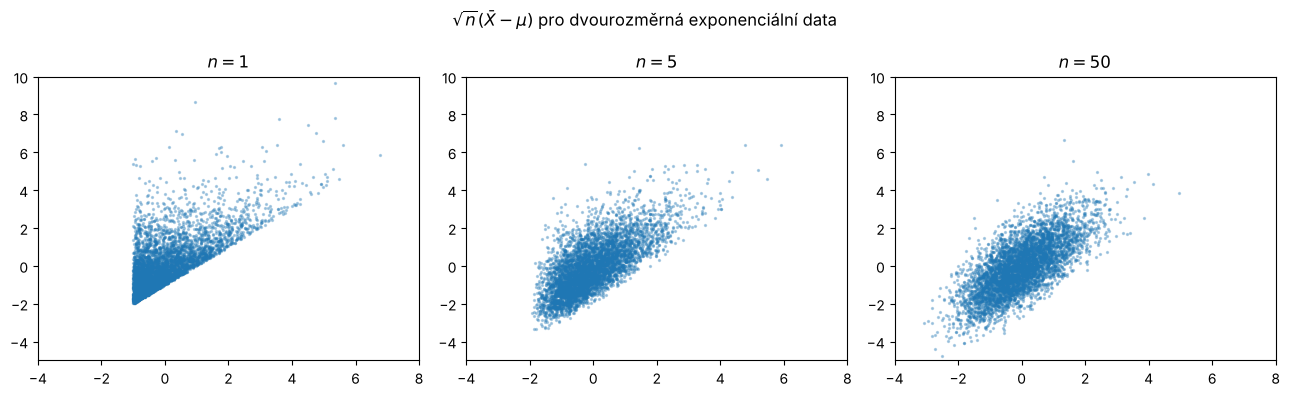

In [14]:
mu = np.array([1.0, 2.0]); Sig = np.array([[1.0, 1.0], [1.0, 2.0]])
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, n_clt in zip(ax, [1, 5, 50]):
    E1 = RNG.exponential(size=(5000, n_clt)); E2 = RNG.exponential(size=(5000, n_clt))
    M = np.stack([E1.mean(1), (E1 + E2).mean(1)], axis=1)
    U = np.sqrt(n_clt) * (M - mu)
    a.scatter(U[:, 0], U[:, 1], s=2, alpha=0.3)
    a.set_title(f"$n={n_clt}$"); a.set_xlim(-4, 8); a.set_ylim(-5, 10)
    print(f"n={n_clt:2d}: výběrová var. matice sqrt(n)(xbar-mu):", np.cov(U, rowvar=False).round(2).tolist())
plt.suptitle(r"$\sqrt{n}(\bar{X}-\mu)$ pro dvourozměrná exponenciální data"); plt.tight_layout(); plt.show()

Varianční matice $\sqrt n(\bar{\boldsymbol X}-\boldsymbol\mu)$ je pro každé $n$ rovna $\boldsymbol\Sigma$; s rostoucím $n$ se mění tvar rozdělení – mizí asymetrie a mrak bodů se blíží eliptickému tvaru.

# 6. Wishartovo a Hotellingovo rozdělení

* $(n-1)S\sim W_k(\boldsymbol\Sigma,n-1)$, $\mathrm{E} M=m\boldsymbol\Sigma$ pro $M\sim W_k(\boldsymbol\Sigma,m)$,
* $n(\bar{\boldsymbol X}-\boldsymbol\mu)^TS^{-1}(\bar{\boldsymbol X}-\boldsymbol\mu)\sim T^2(k,n-1)=\frac{(n-1)k}{n-k}F(k,n-k)$.

In [15]:
from scipy.stats import wishart
m = 9
Wsamp = wishart(df=m, scale=Sigma).rvs(size=20000, random_state=1)
print("průměr Wishartových matic:\n", Wsamp.mean(axis=0))
print("m * Sigma:\n", m * Sigma)

průměr Wishartových matic:
 [[18.0609  7.2514]
 [ 7.2514  9.0166]]
m * Sigma:
 [[18.   7.2]
 [ 7.2  9. ]]


In [16]:
n_h, k_h = 10, 3
Sig3 = np.array([[1, .5, .2], [.5, 1, .3], [.2, .3, 1]])
T2 = []
for _ in range(20000):
    Y = RNG.multivariate_normal(np.zeros(3), Sig3, n_h)
    d = Y.mean(0)
    T2.append(n_h * d @ np.linalg.solve(np.cov(Y, rowvar=False), d))
T2 = np.array(T2)
F_scaled = (n_h - k_h) / ((n_h - 1) * k_h) * T2
print("podíl F > F_0.95:", np.mean(F_scaled > stats.f.ppf(0.95, k_h, n_h - k_h)))
print("podíl T2 > chi2_0.95 (nesprávná aproximace):", np.mean(T2 > stats.chi2.ppf(0.95, k_h)))

podíl F > F_0.95: 0.0491
podíl T2 > chi2_0.95 (nesprávná aproximace): 0.1976


Přepočtená statistika překročí kvantil $F_{0,95}(3,7)$ přibližně v 5 % případů, jak má. Pokud bychom pro malé $n=10$ použili asymptotické rozdělení $\chi^2_3$, zamítali bychom mnohem častěji (asi ve 20 % případů) – rozdíl mezi $S$ a $\boldsymbol\Sigma$ nelze zanedbat.

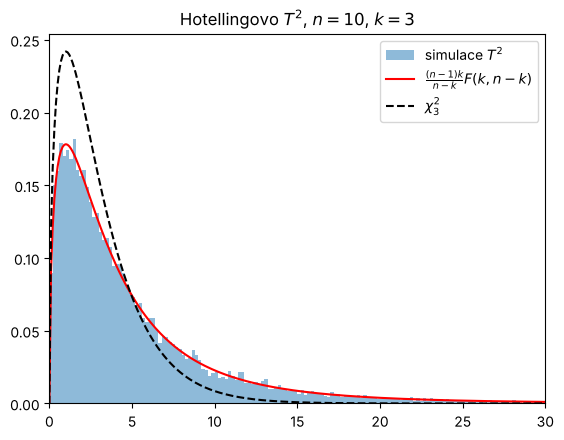

In [17]:
x = np.linspace(0, 40, 400)
dens = stats.f.pdf(x * (n_h - k_h) / ((n_h - 1) * k_h), k_h, n_h - k_h) * (n_h - k_h) / ((n_h - 1) * k_h)
plt.hist(T2, bins=200, range=(0, 40), density=True, alpha=0.5, label="simulace $T^2$")
plt.plot(x, dens, "r", label=r"$\frac{(n-1)k}{n-k}F(k,n-k)$")
plt.plot(x, stats.chi2.pdf(x, k_h), "k--", label=r"$\chi^2_3$")
plt.legend(); plt.xlim(0, 30); plt.title("Hotellingovo $T^2$, $n=10$, $k=3$"); plt.show()

# 7. Jednorozměrná vizualizace

### Histogram – pravidla pro počet tříd

In [18]:
x = X[:, 0]
for pravidlo in ["sturges", "scott", "fd"]:
    hrany = np.histogram_bin_edges(x, bins=pravidlo)
    print(f"{pravidlo:8s}: {len(hrany) - 1:2d} tříd, šířka {hrany[1] - hrany[0]:.3f}")
print("Sturges ručně:", int(np.ceil(1 + np.log2(n))))
print("Scott ručně h =", 3.49 * x.std(ddof=1) / n ** (1 / 3))
q1, q3 = np.percentile(x, [25, 75]); print("FD ručně h =", 2 * (q3 - q1) / n ** (1 / 3))

sturges :  9 tříd, šířka 0.400
scott   :  7 tříd, šířka 0.514
fd      :  8 tříd, šířka 0.450
Sturges ručně: 9
Scott ručně h = 0.5439095623847782
FD ručně h = 0.48933873501813513


NumPy používá ve Scottově pravidle konstantu $(24\sqrt\pi)^{1/3}\approx3{,}49$, v přednášce je zaokrouhleně 3,5. Počet tříd se pak dopočítá z rozpětí dat.

### Jádrový odhad hustoty – vliv šířky pásma $h$

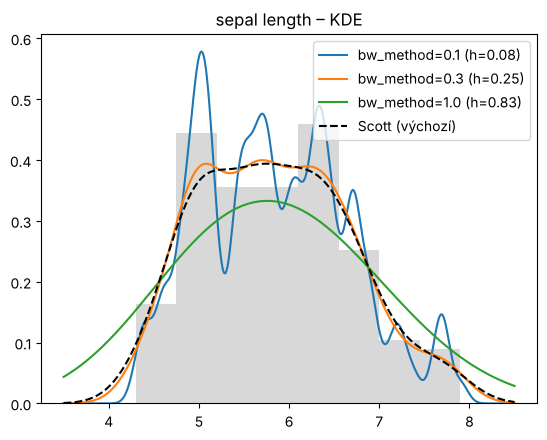

In [19]:
from scipy.stats import gaussian_kde
grid = np.linspace(3.5, 8.5, 400)
plt.hist(x, bins="fd", density=True, alpha=0.3, color="gray")
for bw in [0.1, 0.3, 1.0]:
    kde = gaussian_kde(x, bw_method=bw)
    plt.plot(grid, kde(grid), label=f"bw_method={bw} (h={kde.factor * x.std(ddof=1):.2f})")
plt.plot(grid, gaussian_kde(x)(grid), "k--", label="Scott (výchozí)")
plt.legend(); plt.title("sepal length – KDE"); plt.show()

Malé $h$ dává členitou křivku (přeučení), velké $h$ přehladí – z odhadu zmizí plochý vrchol a náznak více vrcholů (data jsou směsí tří druhů) a křivka se blíží jedné normální hustotě.

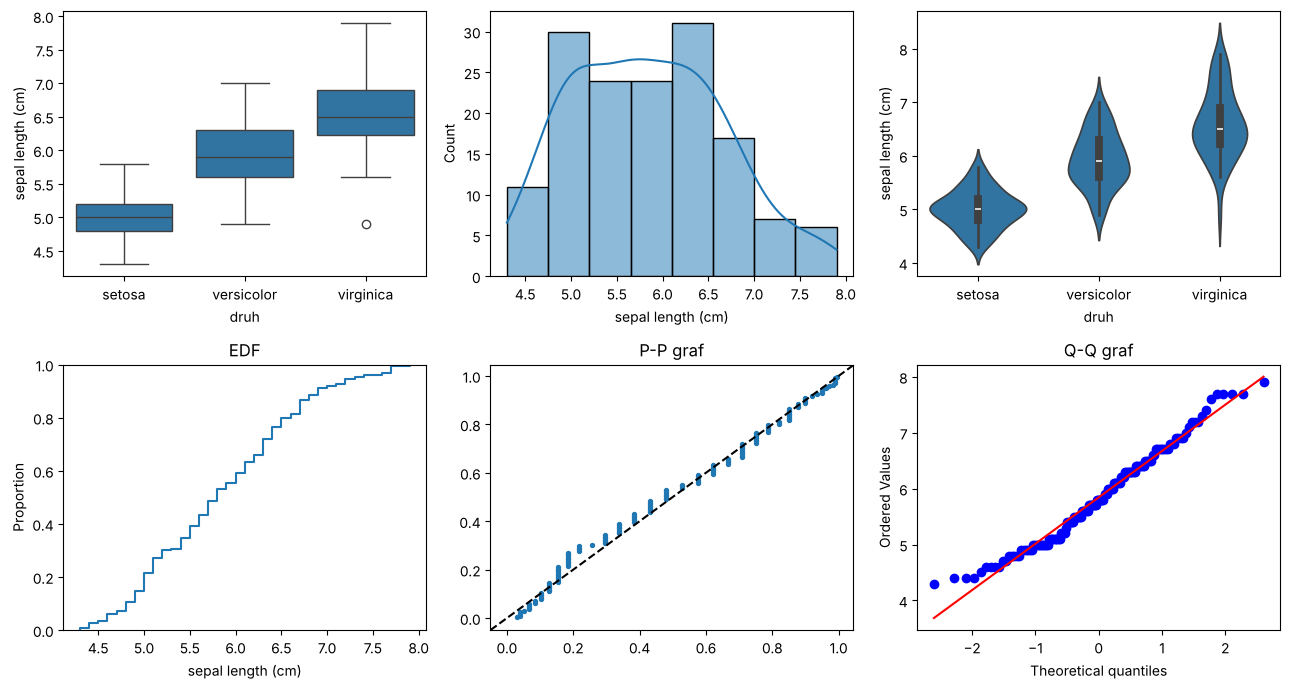

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
sns.boxplot(data=df, x="druh", y="sepal length (cm)", ax=ax[0, 0])
sns.histplot(df["sepal length (cm)"], bins="fd", kde=True, ax=ax[0, 1])
sns.violinplot(data=df, x="druh", y="sepal length (cm)", ax=ax[0, 2])
sns.ecdfplot(df["sepal length (cm)"], ax=ax[1, 0]); ax[1, 0].set_title("EDF")
# P-P graf proti normálnímu rozdělení s odhadnutými parametry
xs = np.sort(x); p = (np.arange(1, n + 1) - 0.5) / n
ax[1, 1].scatter(stats.norm.cdf(xs, x.mean(), x.std(ddof=1)), p, s=8)
ax[1, 1].axline((0, 0), slope=1, color="k", ls="--"); ax[1, 1].set_title("P-P graf")
stats.probplot(x, dist="norm", plot=ax[1, 2]); ax[1, 2].set_title("Q-Q graf")
plt.tight_layout(); plt.show()

# 8. Vícerozměrná vizualizace

### Elipsy: oblast pro pozorování a konfidenční oblast pro $\boldsymbol\mu$

* přibližně $100(1-\alpha)\,\%$ pozorování leží v elipse $d^2\leq\chi^2_k(1-\alpha)$,
* konfidenční oblast pro $\boldsymbol\mu$: $n(\bar{\boldsymbol x}-\boldsymbol\mu)^TS^{-1}(\bar{\boldsymbol x}-\boldsymbol\mu)\leq\frac{(n-1)k}{n-k}F_{1-\alpha}(k,n-k)$.

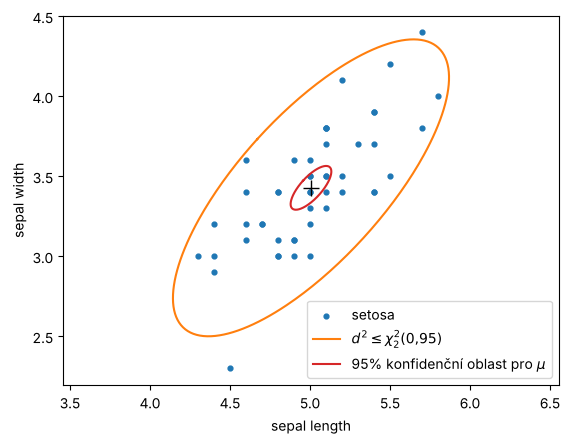

podíl bodů uvnitř 95% elipsy: 0.96


In [21]:
def elipsa(stred, M, c, **kw):
    # body (x - stred)^T M^{-1} (x - stred) = c
    lam, V = np.linalg.eigh(M)
    t = np.linspace(0, 2 * np.pi, 300)
    kruh = np.stack([np.cos(t), np.sin(t)])
    E = V @ np.diag(np.sqrt(lam * c)) @ kruh
    plt.plot(stred[0] + E[0], stred[1] + E[1], **kw)

Y2 = Xs[:, :2]                                  # setosa, sepal length a width
n2, k2 = Y2.shape
m2, S2 = Y2.mean(0), np.cov(Y2, rowvar=False)
plt.scatter(Y2[:, 0], Y2[:, 1], s=12, label="setosa")
elipsa(m2, S2, stats.chi2.ppf(0.95, 2), color="C1", label=r"$d^2 \leq \chi^2_2(0{,}95)$")
c_mu = (n2 - 1) * k2 / (n2 - k2) * stats.f.ppf(0.95, k2, n2 - k2) / n2
elipsa(m2, S2, c_mu, color="C3", label=r"95% konfidenční oblast pro $\mu$")
plt.plot(*m2, "k+", ms=12)
plt.xlabel("sepal length"); plt.ylabel("sepal width"); plt.legend(); plt.axis("equal"); plt.show()

d2 = np.einsum("ij,jk,ik->i", Y2 - m2, np.linalg.inv(S2), Y2 - m2)
print("podíl bodů uvnitř 95% elipsy:", np.mean(d2 <= stats.chi2.ppf(0.95, 2)))

Konfidenční oblast pro $\boldsymbol\mu$ je mnohem menší než elipsa pro pozorování (zhruba $\sqrt n$-krát), protože $\mathrm{Var}\bar{\boldsymbol X}=\boldsymbol\Sigma/n$.

### Q-Q graf Mahalanobisových vzdáleností

Přesně: $\frac{n}{(n-1)^2}d_i^2\sim Beta\left(\frac k2,\frac{n-k-1}2\right)$, asymptoticky $d_i^2\approx\chi^2_k$.

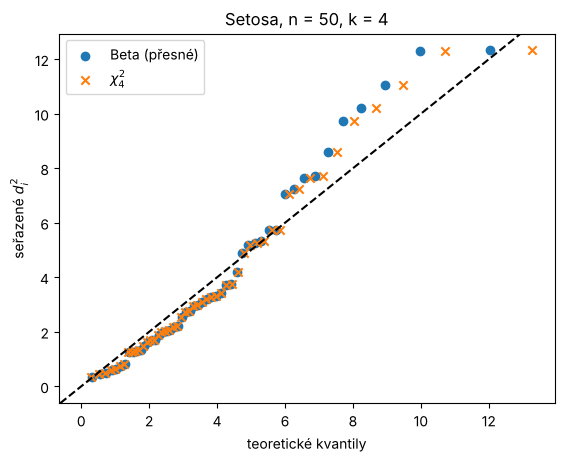

součet d_i^2 = 196.0000000000001  (vždy (n-1)k = 196 )
max d^2 = 12.327638663921592  max možné (n-1)^2/n = 48.02


In [22]:
D = Xs - Xs.mean(0)
d2 = np.einsum("ij,jk,ik->i", D, np.linalg.inv(np.cov(Xs, rowvar=False)), D)
ns, ks = Xs.shape
p = (np.arange(1, ns + 1) - 0.5) / ns
q_beta = (ns - 1) ** 2 / ns * stats.beta.ppf(p, ks / 2, (ns - ks - 1) / 2)
q_chi2 = stats.chi2.ppf(p, ks)
plt.scatter(q_beta, np.sort(d2), label="Beta (přesné)")
plt.scatter(q_chi2, np.sort(d2), marker="x", label=r"$\chi^2_4$")
plt.axline((0, 0), slope=1, color="k", ls="--"); plt.legend()
plt.xlabel("teoretické kvantily"); plt.ylabel(r"seřazené $d_i^2$"); plt.title("Setosa, n = 50, k = 4"); plt.show()
print("součet d_i^2 =", d2.sum(), " (vždy (n-1)k =", (ns - 1) * ks, ")")
print("max d^2 =", d2.max(), " max možné (n-1)^2/n =", (ns - 1) ** 2 / ns)

Body leží zhruba podél diagonály – ve střední části mírně pod ní, nejvyšší hodnoty nad ní. U setosy je tedy několik pozorování s neobvyklou kombinací hodnot (těžší chvost), výrazně odlehlé pozorování ale nevidíme. Všimněte si, že $\sum_i d_i^2=(n-1)k$ platí vždy (stopa $S^{-1}\cdot(n-1)S$) a $d_i^2\le\frac{(n-1)^2}{n}$, takže $\chi^2$ aproximace u malých $n$ nadhodnocuje horní kvantily.

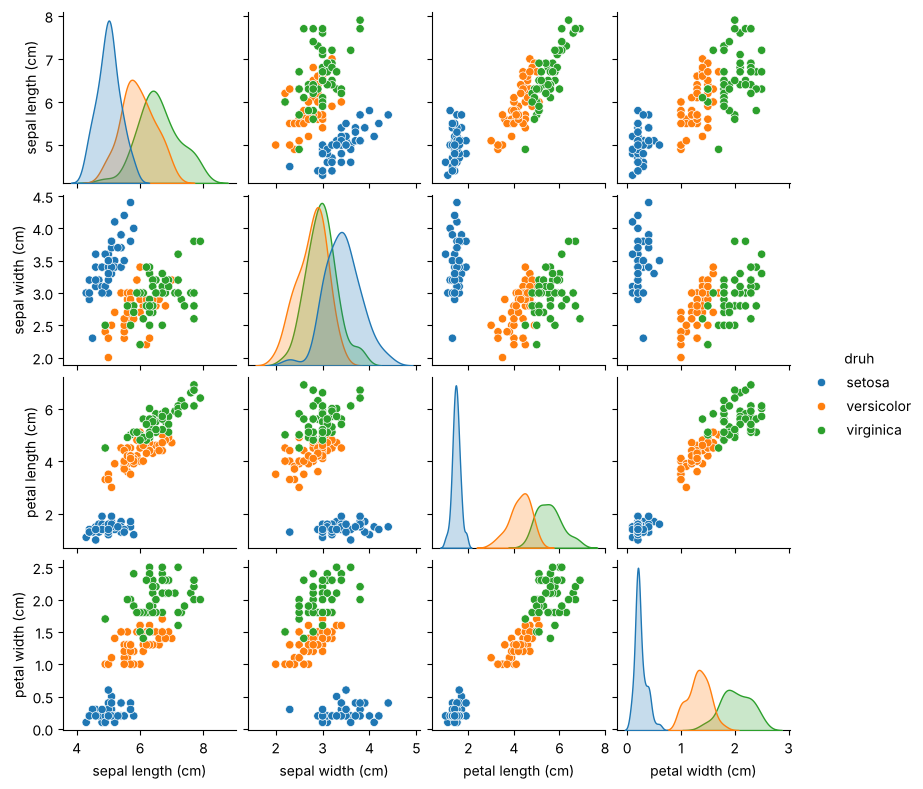

In [23]:
sns.pairplot(df.drop(columns="target"), hue="druh", height=2.0)
plt.show()

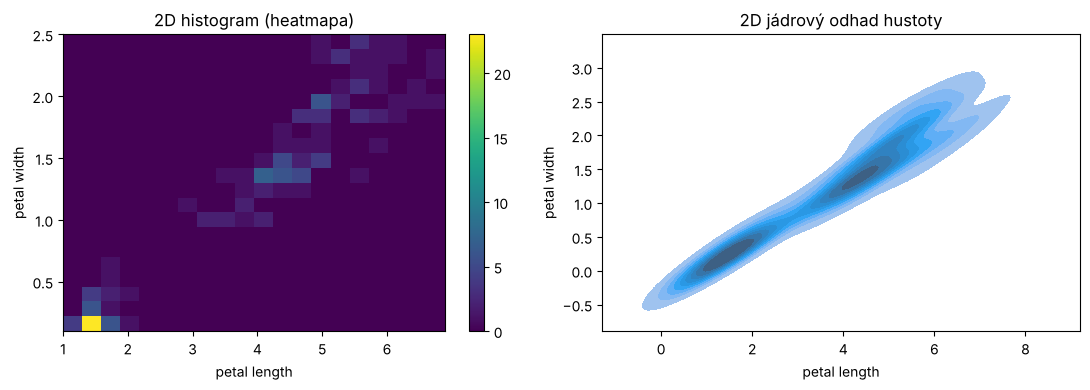

In [24]:
u, v = X[:, 2], X[:, 3]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h = ax[0].hist2d(u, v, bins=20, cmap="viridis"); plt.colorbar(h[3], ax=ax[0])
ax[0].set_title("2D histogram (heatmapa)")
sns.kdeplot(x=u, y=v, fill=True, ax=ax[1]); ax[1].set_title("2D jádrový odhad hustoty")
for a in ax: a.set_xlabel("petal length"); a.set_ylabel("petal width")
plt.tight_layout(); plt.show()

Dvourozměrný histogram i jádrový odhad ukazují dva oddělené shluky – setosa a dvojice versicolor + virginica.

# 9. Úlohy

1. Ověřte simulací, že standardizace `StandardScaler` vede k výběrovým rozptylům $\frac{n}{n-1}$ (ne 1), pokud je počítáme s dělitelem $n-1$.
2. Pro data Iris (všechny tři druhy) spočtěte Mahalanobisovy vzdálenosti a nakreslete Q-Q graf. Proč je odchylka od diagonály mnohem větší než pro samotnou setosu?
3. Simulací ověřte, že $\mathrm{E} d_i^2=\frac{(n-1)k}{n}$ (průměr Mahalanobisových vzdáleností v rámci jednoho výběru je dokonce přesně roven této hodnotě – proč?).
4. Pro $n=20$, $k=5$ porovnejte simulací skutečnou hladinu testu založeného na $T^2$ s kritickou hodnotou z rozdělení $\chi^2_5$ a z přesného rozdělení $F$.
5. Pro proměnnou *petal length* porovnejte počty tříd podle pravidel Sturges, Scott a Freedman–Diaconis. Které pravidlo nejlépe zachytí bimodalitu?